**A. Membangun Struktur Direktori HDFS**(bobot 15%)

Buatlah struktur direktori berikut di HDFS:
```
/user/[username]/ecommerce/raw
/user/[username]/ecommerce/processed
```
Tampilkan hasilnya untuk membuktikan struktur sudah terbentuk.

In [2]:
# Membuat struktur direktori raw dan processed di HDFS
!hdfs dfs -mkdir -p /user/vboxuser/ecommerce/raw
!hdfs dfs -mkdir -p /user/vboxuser/ecommerce/processed

# Menampilkan struktur folder yang telah dibuat
!hdfs dfs -ls -R /user/vboxuser/ecommerce

drwxr-xr-x   - vboxuser supergroup          0 2026-09-13 01:02 /user/vboxuser/ecommerce/processed
drwxr-xr-x   - vboxuser supergroup          0 2026-09-13 01:02 /user/vboxuser/ecommerce/raw


**B. Mengunggah Data Mentah ke HDFS** *(bobot 15%)*

Unggah **ketiga berkas CSV** (`transaksi_magelang.csv`, `transaksi_yogyakarta.csv`, `transaksi_semarang.csv`) ke direktori `/user/[username]/ecommerce/raw` di HDFS. Tampilkan isi direktori tersebut sebagai bukti ketiga berkas berhasil terunggah, lengkap dengan ukurannya.

In [11]:
# Mengunggah ketiga file CSV ke direktori raw
!hdfs dfs -put transaksi_magelang.csv /user/vboxuser/ecommerce/raw/
!hdfs dfs -put transaksi_yogyakarta.csv /user/vboxuser/ecommerce/raw/
!hdfs dfs -put transaksi_semarang.csv /user/vboxuser/ecommerce/raw/

# Memeriksa isi folder raw beserta ukurannya
!hdfs dfs -ls -h /user/vboxuser/ecommerce/raw

put: `/user/vboxuser/ecommerce/raw/transaksi_magelang.csv': File exists
put: `/user/vboxuser/ecommerce/raw/transaksi_yogyakarta.csv': File exists
put: `/user/vboxuser/ecommerce/raw/transaksi_semarang.csv': File exists
Found 3 items
-rw-r--r--   3 vboxuser supergroup     12.0 K 2026-09-13 02:09 /user/vboxuser/ecommerce/raw/transaksi_magelang.csv
-rw-r--r--   3 vboxuser supergroup     11.9 K 2026-09-13 02:09 /user/vboxuser/ecommerce/raw/transaksi_semarang.csv
-rw-r--r--   3 vboxuser supergroup     12.4 K 2026-09-13 02:09 /user/vboxuser/ecommerce/raw/transaksi_yogyakarta.csv


**C. Membaca Kembali dan Menggabungkan Data dari HDFS** *(bobot 25%)*

Menggunakan Python, baca kembali **ketiga berkas dari HDFS** (bukan dari disk lokal!). Gabungkan ketiganya menjadi **satu DataFrame**, lalu buktikan hasil gabungan berisi transaksi dari ketiga kota (tampilkan `value_counts()` pada kolom `kota`).

In [12]:
!pip install fsspec pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.7 MB/s  0:00:04 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fsspec]━━━━ 1/2 [fsspec]


In [14]:
import pandas as pd

# 1. Buat folder sementara dan unduh file dari HDFS ke lokal
!mkdir -p temp_data
!hdfs dfs -get /user/vboxuser/ecommerce/raw/*.csv temp_data/

# 2. Baca ketiga file CSV dengan Pandas dari folder lokal
df_magelang = pd.read_csv('temp_data/transaksi_magelang.csv')
df_yogyakarta = pd.read_csv('temp_data/transaksi_yogyakarta.csv')
df_semarang = pd.read_csv('temp_data/transaksi_semarang.csv')

# 3. Gabungkan menjadi satu DataFrame
df_gabungan = pd.concat([df_magelang, df_yogyakarta, df_semarang], ignore_index=True)

# 4. Tampilkan jumlah transaksi per kota
print("Jumlah transaksi per kota:")
print(df_gabungan['kota'].value_counts())

Jumlah transaksi per kota:
kota
Magelang      200
Yogyakarta    200
Semarang      200
Name: count, dtype: int64


**D. Mengolah dan Download Hasil ke Direktori `processed`** *(bobot 25%)*

Pada DataFrame gabungan hasil bagian C:
1. Tambahkan kolom `total_pendapatan` (`unit_terjual x harga_satuan`).
2. Buatlah **satu tabel ringkasan** (`groupby`) yang menampilkan total pendapatan per kota **dan** per kategori sekaligus.
3. Simpan **dua** hasil berikut sebagai berkas CSV baru di disk lokal, lalu unggah keduanya ke `/user/[username]/ecommerce/processed` di HDFS:
   - `data_gabungan_bersih.csv` (seluruh data ketiga kota yang telah digabung + kolom `total_pendapatan`)
   - `ringkasan_kota_kategori.csv` (tabel ringkasan dari langkah 2)

In [21]:
# 1. Tambahkan kolom total_pendapatan
df_gabungan['total_pendapatan'] = df_gabungan['unit_terjual'] * df_gabungan['harga_satuan']

# 2. Buat tabel ringkasan (groupby) total pendapatan per kota dan kategori
ringkasan = df_gabungan.groupby(['kota', 'kategori'])['total_pendapatan'].sum().reset_index()

# Tampilkan hasil ringkasan agar kita bisa melihatnya
print("Tabel Ringkasan Pendapatan per Kota dan Kategori:")
display(ringkasan)

# 3. Simpan hasil ke CSV lokal
df_gabungan.to_csv('data_gabungan_bersih.csv', index=False)
ringkasan.to_csv('ringkasan_kota_kategori.csv', index=False)

# 4. Pastikan folder processed ada, lalu upload kedua file hasil ke HDFS
!hdfs dfs -mkdir -p /user/vboxuser/ecommerce/processed
!hdfs dfs -put data_gabungan_bersih.csv /user/vboxuser/ecommerce/processed/
!hdfs dfs -put ringkasan_kota_kategori.csv /user/vboxuser/ecommerce/processed/

# 5. Verifikasi hasil di HDFS (pastikan file sudah masuk)
!hdfs dfs -ls -h /user/vboxuser/ecommerce/processed

Tabel Ringkasan Pendapatan per Kota dan Kategori:


,kota,kategori,total_pendapatan
0,Magelang,Elektronik,18775000
1,Magelang,Fashion,27750000
2,Magelang,Kesehatan & Kecantikan,17375000
3,Magelang,Makanan & Minuman,17525000
4,Magelang,Rumah Tangga,12200000
5,Semarang,Elektronik,21425000
6,Semarang,Fashion,26425000
7,Semarang,Kesehatan & Kecantikan,13525000
8,Semarang,Makanan & Minuman,19750000
9,Semarang,Rumah Tangga,10975000


put: `/user/vboxuser/ecommerce/processed/data_gabungan_bersih.csv': File exists
put: `/user/vboxuser/ecommerce/processed/ringkasan_kota_kategori.csv': File exists
Found 2 items
-rw-r--r--   3 vboxuser supergroup     40.3 K 2026-09-13 03:30 /user/vboxuser/ecommerce/processed/data_gabungan_bersih.csv
-rw-r--r--   3 vboxuser supergroup        530 2026-09-13 03:30 /user/vboxuser/ecommerce/processed/ringkasan_kota_kategori.csv


**E. Dokumentasi dan Refleksi** *(bobot 20%)*

Sertakan pada notebook anda:
1. **Screenshot** halaman NameNode Web UI (http://localhost:9870, menu *Utilities → Browse the file system*) yang menunjukkan struktur folder `/user/[username]/ecommerce/` beserta isinya (paste gambar ke dalam markdown cell, atau lampirkan terpisah jika format pengumpulan berupa arsip/zip.


2. Tulisan reflektif (**minimal 100 kata**) pada markdown cell yang menjawab: *Apa keuntungan menyimpan data mentah (raw) terpisah dari data olahan (processed) di HDFS, dibandingkan menyimpan semuanya bercampur dalam satu folder?*


### Screenshot

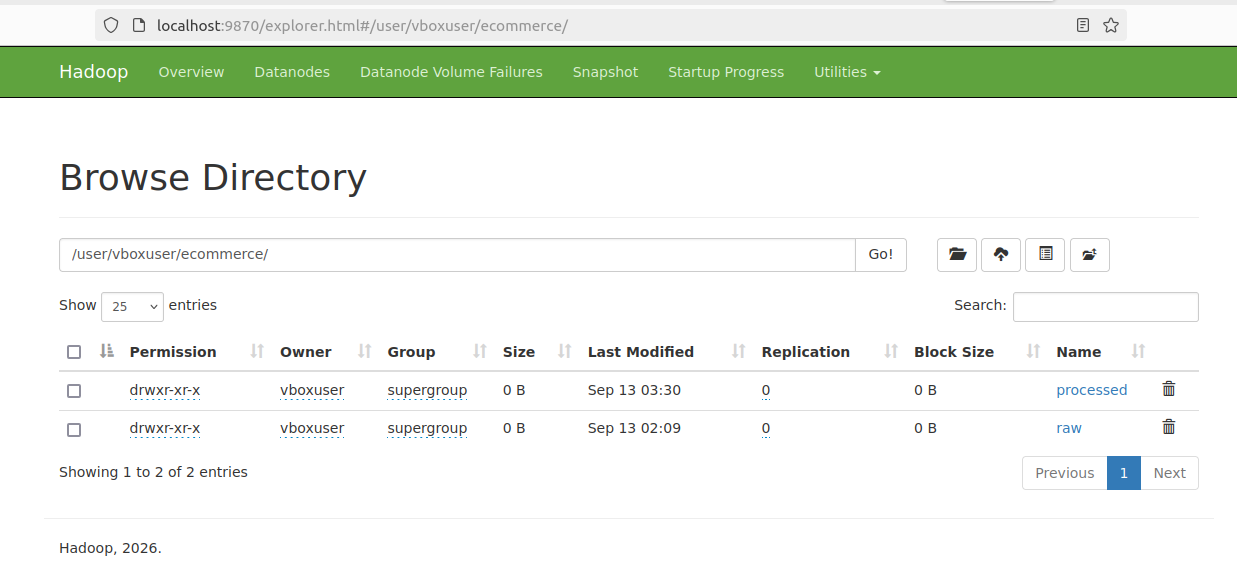
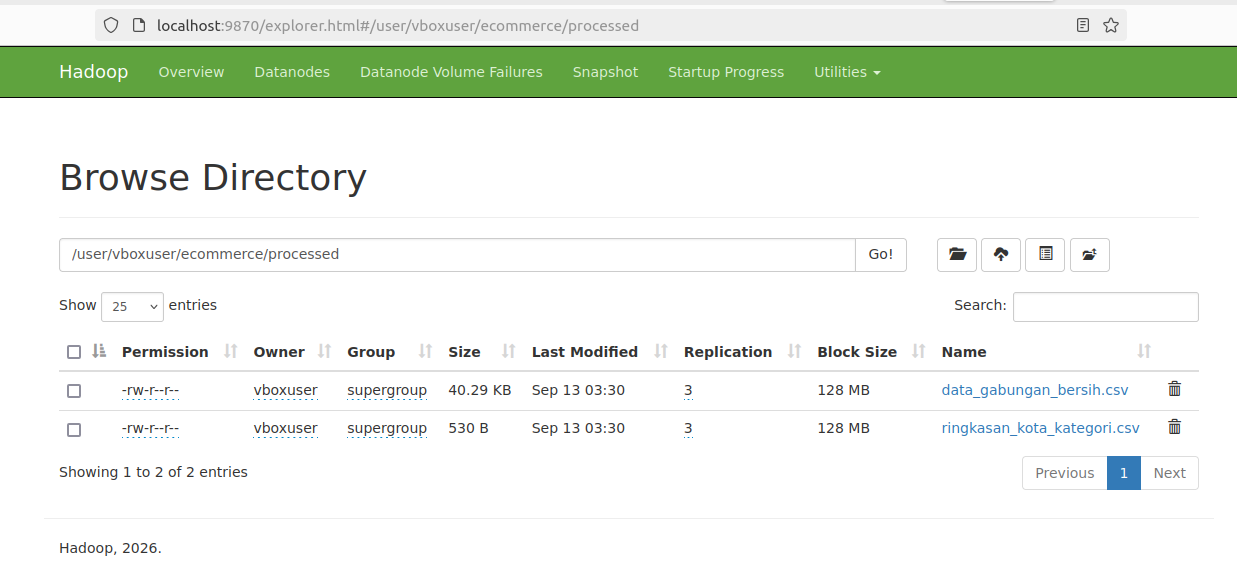

### 2. Refleksi Pemisahan Data Raw dan Processed
```
    Memisahkan data mentah (raw) dan data yang sudah diolah (processed) di dalam HDFS sangat penting dalam arsitektur Big Data. Data mentah berfungsi sebagai sumber kebenaran (source of truth) yang tidak boleh diubah, sehingga jika terjadi kesalahan pada logika pengolahan, kita dapat mengulang proses dari awal tanpa kehilangan data asli. Kedua, struktur ini menjaga kerapian alur kerja (data pipeline), sehingga analis atau data engineer lain dapat dengan mudah mengidentifikasi mana data yang siap pakai untuk dashboarding dan mana data yang masih perlu tahapan cleaning. Terakhir, pemisahan ini memudahkan pengaturan hak akses, di mana hanya sistem atau engineer tertentu yang boleh menulis di folder raw, sementara pengguna bisnis hanya diizinkan membaca dari folder processed.